# Question 1 — Linear Regression from first principles

This notebook trains the central NumPy implementation in `src/q1_models.py`. It does not redefine or substitute the algorithm. Data generation, splitting, training, numerical checking and evaluation are separate executable steps. All labels and values below come from this execution.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (root / 'src').is_dir(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(root))
from src.q1_models import LinearRegressionGD, gradient_check
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
%matplotlib inline

## Model and objective
For $X\in\mathbb{R}^{m\times d}$, $w\in\mathbb{R}^d$, $b\in\mathbb{R}$, predict $\hat y=Xw+b$. Define $e_i=x_i^Tw+b-y_i$ and $J=\frac{1}{2m}\sum_i e_i^2$. The chain rule gives $\frac{\partial J}{\partial w_j}=\frac{1}{m}\sum_i e_i x_{ij}$ and $\frac{\partial J}{\partial b}=\frac{1}{m}\sum_i e_i$. The one-half convention simplifies the derivative without changing the optimum.

## Inspect the actual shared implementation
The source below is the code used by both the experiment script and this notebook. No sklearn estimator trains this scratch model.

In [2]:
print(inspect.getsource(LinearRegressionGD))

class LinearRegressionGD:
    """Minimize J=(1/(2m)) sum_i (X_i @ w + b - y_i)^2."""

    def __init__(self, learning_rate=0.08, epochs=1200):
        self.learning_rate, self.epochs = learning_rate, epochs

    def _loss_grad(self, X, y, w, b):
        err = X @ w + b - y
        return float(np.mean(err**2) / 2), X.T @ err / len(y), float(np.mean(err))

    def fit(self, X, y):
        X, y = training_inputs(X, y, self.learning_rate, self.epochs)
        self.weights_ = np.zeros(X.shape[1])
        self.bias_ = 0.0
        self.loss_history_ = [self._loss_grad(X, y, self.weights_, self.bias_)[0]]
        for epoch in range(self.epochs):
            loss, dw, db = self._loss_grad(X, y, self.weights_, self.bias_)
            if (
                not np.isfinite(loss)
                or not np.isfinite(dw).all()
                or not np.isfinite(db)
            ):
                raise FloatingPointError(
                    "Gradient Descent diverged; inspect scale and learning rate"


## Generate data and protect the test set
Scaling is fitted after splitting, using training features only. Synthetic Q1 datasets are permitted by the original assignment.

In [3]:
rng = np.random.default_rng(42)
X = rng.normal(size=(360, 2))
y = 4 + 3 * X[:, 0] - 2 * X[:, 1] + rng.normal(0, .65, len(X))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
print("Train/test:", X_train.shape, X_test.shape)
print("Train-fitted scaler mean:", scaler.mean_)

Train/test: (288, 2) (72, 2)
Train-fitted scaler mean: [-0.03272676 -0.04899603]


## Perform full-batch Gradient Descent
Zero initialization is deterministic. Each update subtracts the gradient computed at the current weights and intercept. Loss history includes the initial parameters and the final update.

Initial/final objective: 13.728956347781212 0.20977085928071595
Central finite difference max absolute error: 1.1996528215263424e-09
Final gradient norm: 3.639432274417654e-15


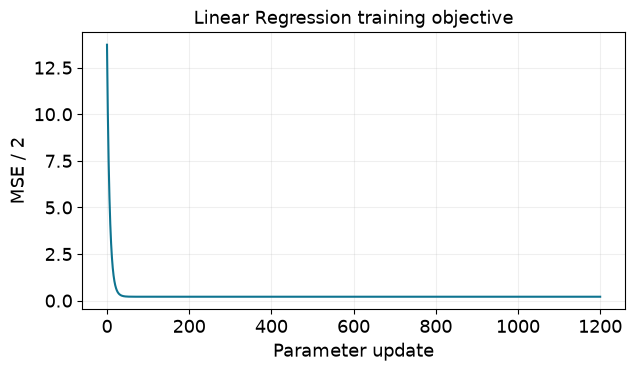

In [4]:
model = LinearRegressionGD().fit(X_train, y_train)
error = gradient_check(LinearRegressionGD(), X_train[:20], y_train[:20])
assert error < 1e-7
print("Initial/final objective:", model.loss_history_[0], model.loss_history_[-1])
print("Central finite difference max absolute error:", error)
print("Final gradient norm:", model.gradient_norm_)
plt.figure(figsize=(7, 3.6))
plt.plot(model.loss_history_, color="#0E7490")
plt.xlabel("Parameter update")
plt.ylabel("MSE / 2")
plt.title("Linear Regression training objective")
plt.grid(alpha=.2)
plt.show()

## Evaluate the fixed model on held-out data
MSE is squared target error; RMSE and MAE have target units. R² compares test error against the test-mean baseline.

mse     0.417594
rmse    0.646215
mae     0.504040
r2      0.965492
Name: Test result, dtype: float64

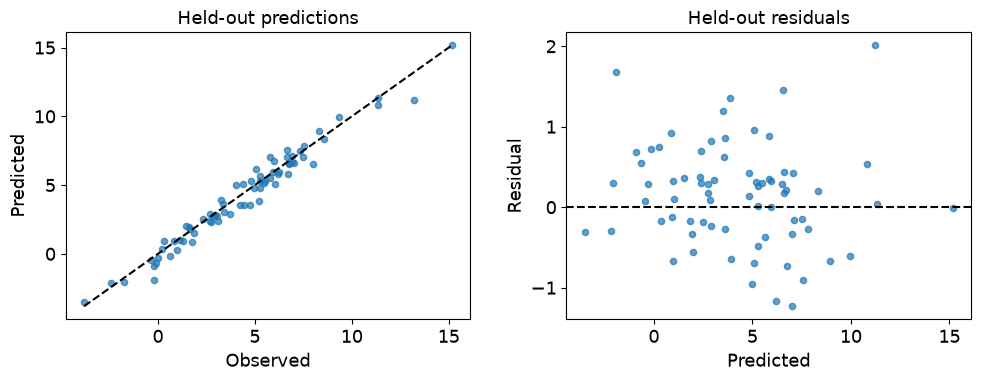

In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
pred = model.predict(X_test)
measured = dict(mse=mean_squared_error(y_test, pred), rmse=np.sqrt(mean_squared_error(y_test, pred)), mae=mean_absolute_error(y_test, pred), r2=r2_score(y_test, pred))
display(pd.Series(measured, name="Test result"))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_test, pred, s=20, alpha=.7)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "k--")
axes[0].set(xlabel="Observed", ylabel="Predicted", title="Held-out predictions")
axes[1].scatter(pred, y_test-pred, s=20, alpha=.7)
axes[1].axhline(0, color="black", ls="--")
axes[1].set(xlabel="Predicted", ylabel="Residual", title="Held-out residuals")
plt.tight_layout(); plt.show()

## Independent validation benchmark
The least-squares reference is evaluated separately. It never supplies coefficients to the submitted Gradient Descent model.

In [6]:
from sklearn.linear_model import LinearRegression
reference = LinearRegression().fit(X_train, y_train)
max_difference = np.max(np.abs(reference.predict(X_test)-pred))
print("Reference prediction maximum difference:", max_difference)
assert max_difference < 1e-8

Reference prediction maximum difference: 7.105427357601002e-15


## Trace to the experiment and interpret
These assertions compare the independently executed notebook with the generated experiment JSON. They do not copy the reported scores into the notebook evaluation.

In [7]:
saved = json.loads((root / "results/q1_metrics.json").read_text())["linear"]
for key, value in measured.items():
    assert np.isclose(value, saved[key], rtol=0, atol=1e-12), key
print("Notebook metrics agree with independently executed script.")

Notebook metrics agree with independently executed script.


The low residual error is expected because the true conditional mean is linear. The remaining errors reflect synthetic noise and are not evidence of a defect in optimization. Performance on nonlinear or shifted data is not established.